In [107]:
import nflreadpy as nfl
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Load Next Gen Stats receiving data (2024-2026)
raw_ngs = nfl.load_nextgen_stats([2024, 2025, 2026], stat_type='receiving')
df_ngs = raw_ngs.to_pandas() if hasattr(raw_ngs, 'to_pandas') else raw_ngs.copy()
# FILTER: Keep regular season games AND exclude full-season summary rows (week == 0)
df_ngs_reg = df_ngs[(df_ngs['season_type'] == 'REG') & (df_ngs['week'] != 0)].copy()

# 2. Sum total targets across unique player IDs
player_totals = df_ngs_reg.groupby('player_gsis_id', as_index=False).agg(
    player_display_name=('player_display_name', 'first'),
    total_targets=('targets', 'sum')
)

In [108]:
# 3. Calculate target-weighted averages for the 3 spatial tracking features
spatial_features = ['avg_intended_air_yards', 'avg_cushion', 'avg_yac_above_expectation']

for col in spatial_features:
    weighted_col = (
        df_ngs_reg.groupby('player_gsis_id')
        .apply(lambda g: (g[col] * g['targets']).sum() / g['targets'].sum() if g['targets'].sum() > 0 else None)
        .reset_index(name=col)
    )
    player_totals = player_totals.merge(weighted_col, on='player_gsis_id')

In [109]:
# 4. Filter for minimum sample size (>= 50 targets) and drop NaNs
df_3feat = player_totals[player_totals['total_targets'] >= 50].dropna().copy()

# 5. Standardize the 3-feature matrix
scaler = StandardScaler()
X_scaled_3 = scaler.fit_transform(df_3feat[spatial_features])

C:\Users\samue\Documents\SeansFiles\CondaNav\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\samue\Documents\SeansFiles\CondaNav\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\samue\Documents\SeansFiles\CondaNav\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\samue\Documents\SeansFiles\CondaNav\Lib\site-packages\sklearn\clust

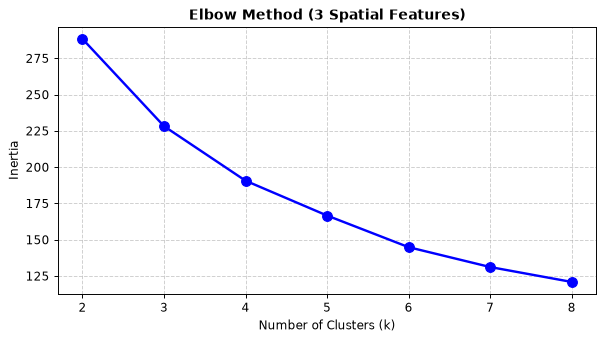

C:\Users\samue\Documents\SeansFiles\CondaNav\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [110]:
# 6. Run and Plot the Elbow Method (Inertia) across k = 2 to 8
k_range = range(2, 9)
inertia_scores = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled_3)
    inertia_scores.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_range, inertia_scores, 'bo-', linewidth=2, markersize=8)
plt.title('Elbow Method (3 Spatial Features)', fontsize=12, fontweight='bold')
plt.xlabel('Number of Clusters (k)', fontsize=10)
plt.ylabel('Inertia', fontsize=10)
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 7. Fit final KMeans model for k=5
kmeans_5 = KMeans(n_clusters=5, random_state=42, n_init=10)
df_3feat['cluster'] = kmeans_5.fit_predict(X_scaled_3)

In [111]:
# 8. Display Heads (Top 5 Players by Target Volume) for Each Cluster
print("\n" + "="*50)
print("--- Cluster Heads (Top Target Earners Per Archetype) ---")
print("="*50)

for c in range(5):
    cluster_df = df_3feat[df_3feat['cluster'] == c].sort_values('total_targets', ascending=False)
    
    print(f"\nCluster {c} (Total Players: {len(cluster_df)})")
    print("-" * 55)
    
    head_table = cluster_df[['player_display_name', 'total_targets', 
                              'avg_intended_air_yards', 'avg_cushion', 'avg_yac_above_expectation']].head(5)
    
    head_table.columns = ['Player', 'Total Targets', 'aDoT', 'Cushion', 'YAC+']
    print(head_table.to_string(index=False))


--- Cluster Heads (Top Target Earners Per Archetype) ---

Cluster 0 (Total Players: 22)
-------------------------------------------------------
            Player  Total Targets      aDoT  Cushion     YAC+
Jaxon Smith-Njigba            365 10.372247 6.059219 0.673335
      Drake London            313 10.660639 6.489154 0.947404
      Malik Nabers            268 10.973731 6.405729 0.386783
     Jakobi Meyers            243  9.588107 6.542201 0.360323
       Rome Odunze            200 13.850550 6.130068 0.984394

Cluster 1 (Total Players: 25)
-------------------------------------------------------
          Player  Total Targets      aDoT  Cushion     YAC+
   Ja'Marr Chase            398  8.800528 5.694237 1.858558
     CeeDee Lamb            337  9.963887 6.114565 1.224147
Justin Jefferson            320 10.917781 5.722709 0.785639
   Davante Adams            300 11.321267 5.392879 0.473447
  George Pickens            274 12.146095 5.443704 1.447918

Cluster 2 (Total Players: 32)
-----

In [112]:
# 9. Calculate Average Spatial Feature Values Per Cluster
cluster_averages = (
    df_3feat.groupby('cluster')[spatial_features]
    .mean()
    .rename(columns={
        'avg_intended_air_yards': 'Mean aDoT',
        'avg_cushion': 'Mean Cushion',
        'avg_yac_above_expectation': 'Mean YAC+'
    })
)

# Add cluster player counts for quick context
cluster_averages['Player Count'] = df_3feat.groupby('cluster').size()

print("=" * 60)
print("--- Cluster Feature Averages (k=5) ---")
print("=" * 60)
print(cluster_averages.round(2).to_string())

--- Cluster Feature Averages (k=5) ---
         Mean aDoT  Mean Cushion  Mean YAC+  Player Count
cluster                                                  
0            12.80          6.40       0.71            22
1            10.63          5.46       1.10            25
2            11.71          6.07      -0.20            32
3             6.79          6.72       1.02            23
4             7.00          5.96       0.25            30


In [114]:
from sklearn.metrics import silhouette_score, silhouette_samples
import numpy as np

# Calculate global silhouette score
sil_score = silhouette_score(X_scaled_3, df_3feat['cluster'])
print(f"Overall Model Silhouette Score: {sil_score:.3f}\n")

# Per-cluster silhouette breakdown
sample_silhouette_values = silhouette_samples(X_scaled_3, df_3feat['cluster'])
df_3feat['silhouette_val'] = sample_silhouette_values

print("--- Average Silhouette Score Per Cluster ---")
for c in range(5):
    c_score = df_3feat[df_3feat['cluster'] == c]['silhouette_val'].mean()
    print(f"Cluster {c}: {c_score:.3f}")

Overall Model Silhouette Score: 0.241

--- Average Silhouette Score Per Cluster ---
Cluster 0: 0.215
Cluster 1: 0.188
Cluster 2: 0.330
Cluster 3: 0.171
Cluster 4: 0.264
